# What's inside the box: the numbers behind the slides

Companion notebook for **HON 4013, "What's inside the box: the technology of AI data centers"** (Dr. Jesse Roberts, Fall 2026).

It reproduces every calculated number and chart in the lecture, slide by slide. Nothing here needs a GPU or a download; it runs in a few seconds on Colab or a laptop.

Most inputs are published figures (vendor specifications, Gartner, NREL, papers). Each section says where its inputs come from; the arithmetic on top of them is ours.

In [1]:
import math
import matplotlib.pyplot as plt

BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"

# NVIDIA H100 SXM, from the datasheet: used on several slides
H100_BF16_FLOPS = 989e12        # dense BF16 tensor-core peak, FLOP/s
H100_FP32_FLOPS = 67e12         # FP32 peak, FLOP/s
H100_WATTS = 700
H100_MEMORY_BANDWIDTH = 3.35e12 # HBM3, bytes/s

## Large models are mostly matrix math

A rough count of the operations Kimi K2 does for each new word at a 4,096-token context, split into matrix multiplies and everything else. Model sizes are from the Kimi K2 model card; the count is our estimate, with the non-matrix work (normalization, activations, softmax) counted generously at about 5 operations per value.

In [2]:
LAYERS, HIDDEN, HEADS = 61, 7168, 64
EXPERT_HIDDEN, ACTIVE_EXPERTS = 2048, 9   # 8 routed experts + 1 shared
QK_DIM, V_DIM, CONTEXT = 192, 128, 4096

# Matrix multiplies: about 2 operations per active weight, plus attention scores and mixing
matrix_ops = 2 * 32e9 + LAYERS * HEADS * 2 * (QK_DIM + V_DIM) * CONTEXT

ops_per_value = 5
other_ops = LAYERS * ops_per_value * (2 * HIDDEN + ACTIVE_EXPERTS * EXPERT_HIDDEN + HEADS * CONTEXT)

print(f"Operations per word: {(matrix_ops + other_ops) / 1e9:.0f} billion")
print(f"Share in matrix multiplies: {matrix_ops / (matrix_ops + other_ops):.1%}")
print(f"Multiply-adds behind one output value: {HIDDEN:,}")

Operations per word: 74 billion
Share in matrix multiplies: 99.9%
Multiply-adds behind one output value: 7,168


## GPUs are efficient and fast at math

The H100 figures are from NVIDIA's datasheet. The Xeon 8480C's FP32 peak is not published, so we compute it from cores x base clock x FP32 operations per cycle (two AVX-512 fused multiply-add units x 16 lanes x 2 operations). Its AMX matrix units are left out.

In [3]:
cpu_cores = 56
cpu_base_clock_hz = 2.0e9
cpu_fp32_ops_per_cycle = 2 * 16 * 2
cpu_watts = 350

cpu_fp32_flops = cpu_cores * cpu_base_clock_hz * cpu_fp32_ops_per_cycle
cpu_fp32_lanes = cpu_cores * 16 * 2

gpu_fp32_per_watt = H100_FP32_FLOPS / H100_WATTS
gpu_bf16_per_watt = H100_BF16_FLOPS / H100_WATTS
cpu_fp32_per_watt = cpu_fp32_flops / cpu_watts

print(f"CPU FP32 peak: {cpu_fp32_flops / 1e12:.1f} TFLOPS from {cpu_fp32_lanes:,} lanes")
print(f"Math per second, GPU vs CPU: {H100_FP32_FLOPS / cpu_fp32_flops:.0f}x (FP32), "
      f"{H100_BF16_FLOPS / cpu_fp32_flops:.0f}x (GPU tensor cores)")
print(f"Math per joule, GPU vs CPU:  {gpu_fp32_per_watt / cpu_fp32_per_watt:.1f}x (FP32), "
      f"{gpu_bf16_per_watt / cpu_fp32_per_watt:.0f}x (GPU tensor cores)")

CPU FP32 peak: 7.2 TFLOPS from 1,792 lanes
Math per second, GPU vs CPU: 9x (FP32), 138x (GPU tensor cores)
Math per joule, GPU vs CPU:  4.7x (FP32), 69x (GPU tensor cores)


## Not every rack is a GPU rack

The "about 15x" on the slide is the low end of a GB200 NVL72 rack (120 kW nominal) divided by the industry-average rack (under 8 kW, Uptime Institute 2024).

In [4]:
gpu_rack_kw = 120
average_rack_kw = 8
print(f"GPU rack / average rack = {gpu_rack_kw / average_rack_kw:.0f}x")

GPU rack / average rack = 15x


## How much of it is GPU today?

Gartner's June 2026 estimate of worldwide data-center electricity by segment (TWh; 2027 is a forecast). These are published figures, not computed; the chart and the year-on-year changes are ours. Gartner notes segments may not add to totals because of rounding.

AI servers added, 2025 -> 2026: 80 TWh
Conventional servers added, 2025 -> 2026: 2 TWh


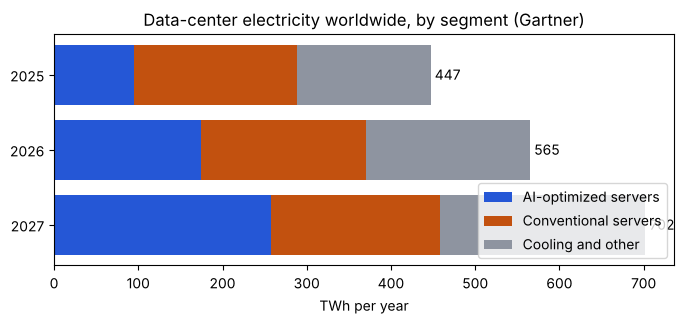

In [5]:
years = ["2025", "2026", "2027"]
ai_servers = [95, 175, 258]
conventional_servers = [193, 195, 200]
cooling_and_other = [159, 195, 243]
totals = [447, 565, 702]

print("AI servers added, 2025 -> 2026:", ai_servers[1] - ai_servers[0], "TWh")
print("Conventional servers added, 2025 -> 2026:", conventional_servers[1] - conventional_servers[0], "TWh")

fig, ax = plt.subplots(figsize=(8, 3))
left = [0, 0, 0]
for values, label, colour in [(ai_servers, "AI-optimized servers", BLUE),
                              (conventional_servers, "Conventional servers", ORANGE),
                              (cooling_and_other, "Cooling and other", GREY)]:
    ax.barh(years, values, left=left, label=label, color=colour)
    left = [l + v for l, v in zip(left, values)]
for year, total in zip(years, totals):
    ax.text(total + 5, year, f"{total}", va="center")
ax.invert_yaxis()
ax.set_xlabel("TWh per year")
ax.set_title("Data-center electricity worldwide, by segment (Gartner)")
ax.legend(loc="lower right")
plt.show()

## What causes the power draw?

Energy per operation on a 45 nm chip (Horowitz, ISSCC 2014, as tabulated by Han et al. 2015). Paper figures, plotted on a log scale; the only calculation is the ratio of a DRAM read to a 32-bit multiply.

DRAM read / 32-bit multiply = 173x


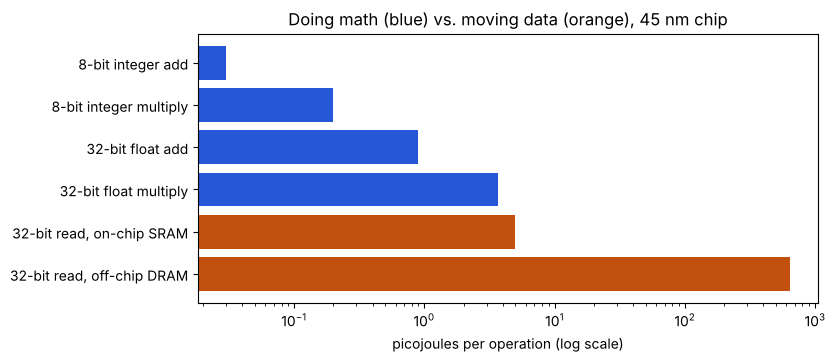

In [6]:
energy_pj = {
    "8-bit integer add": 0.03,
    "8-bit integer multiply": 0.2,
    "32-bit float add": 0.9,
    "32-bit float multiply": 3.7,
    "32-bit read, on-chip SRAM": 5.0,
    "32-bit read, off-chip DRAM": 640.0,
}
is_memory = ["read" in name for name in energy_pj]

print(f"DRAM read / 32-bit multiply = {energy_pj['32-bit read, off-chip DRAM'] / energy_pj['32-bit float multiply']:.0f}x")

fig, ax = plt.subplots(figsize=(8, 3.5))
colours = [ORANGE if memory else BLUE for memory in is_memory]
ax.barh(list(energy_pj), list(energy_pj.values()), color=colours)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("picojoules per operation (log scale)")
ax.set_title("Doing math (blue) vs. moving data (orange), 45 nm chip")
plt.show()

## Every watt in becomes heat

Overhead per 100 kW of computing at each PUE (Google fleet 1.09 in 2024; industry average 1.56, Uptime Institute 2024), and the space-heater comparison for one 130 kW rack. The picture of 87 heaters on the slide uses the same 87.

In [7]:
it_load_kw = 100
for name, pue in [("Google fleet, 2024", 1.09), ("Industry average, 2024", 1.56)]:
    print(f"{name}: {it_load_kw * (pue - 1):.0f} kW of overhead per {it_load_kw} kW of IT")

rack_kw = 130
space_heater_kw = 1.5
print(f"One rack = {rack_kw / space_heater_kw:.0f} space heaters")

Google fleet, 2024: 9 kW of overhead per 100 kW of IT
Industry average, 2024: 56 kW of overhead per 100 kW of IT
One rack = 87 space heaters


## Where the water goes

NREL's median and range of water consumed per MWh generated (Macknick et al. 2012), first for plants with cooling towers and then by cooling type,, converted to litres per kWh so they sit on the same scale as on-site cooling (industry-average WUE 1.9 L/kWh, EESI). Hydropower is shown as about 0: water passes through the turbines. NREL lists 4,491 gal/MWh for hydro, but that is total evaporation from the reservoir surface. Only the extra evaporation the reservoir causes could be charged, and that would need a no-dam landscape to compare against, which is not a real option, so we do not charge it to electricity.

Wind                     0.00 L/kWh  (0.00-0.00)
Solar PV                 0.00 L/kWh  (0.00-0.02)
Gas, cooling tower       0.78 L/kWh  (0.49-1.14)
Nuclear, cooling tower   2.54 L/kWh  (2.20-3.20)
Coal, cooling tower      2.60 L/kWh  (1.82-4.16)
Gas combined cycle   0.0 dry | 0.4 once-through | 0.8 tower L/kWh
Nuclear              1.0 once-through | 2.3 pond | 2.5 tower L/kWh
Coal                 0.9 once-through | 2.6 tower L/kWh
Nuclear once-through withdrawal: 168 L/kWh
100 MW for a day, evaporative cooling on site: 4.6 million L
100 MW for a day, nuclear plant with towers:    6.1 million L


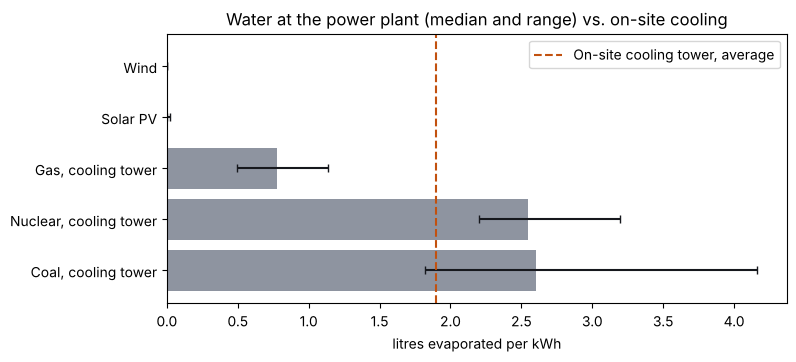

In [8]:
LITRES_PER_GALLON = 3.78541

def gal_per_mwh_to_l_per_kwh(gallons_per_mwh):
    """Convert gallons per MWh to litres per kWh."""
    return gallons_per_mwh * LITRES_PER_GALLON / 1000

plant_gal_per_mwh = {  # (median, min, max)
    "Wind": (0, 0, 0),
    "Solar PV": (1, 0, 5),
    "Gas, cooling tower": (205, 130, 300),
    "Nuclear, cooling tower": (672, 581, 845),
    "Coal, cooling tower": (687, 480, 1100),
}
plant_l_per_kwh = {name: [gal_per_mwh_to_l_per_kwh(v) for v in values]
                   for name, values in plant_gal_per_mwh.items()}
for name, (median, low, high) in plant_l_per_kwh.items():
    print(f"{name:24s} {median:.2f} L/kWh  ({low:.2f}-{high:.2f})")

# The same fuel uses very different amounts depending on how the plant is cooled (NREL medians, gal/MWh)
by_cooling = {
    "Gas combined cycle": {"dry": 2, "once-through": 100, "tower": 205},
    "Nuclear": {"once-through": 269, "pond": 610, "tower": 672},
    "Coal": {"once-through": 250, "tower": 687},
}
for fuel, methods in by_cooling.items():
    parts = [f"{gal_per_mwh_to_l_per_kwh(v):.1f} {method}" for method, v in methods.items()]
    print(f"{fuel:20s}", " | ".join(parts), "L/kWh")

# Once-through cooling evaporates little but withdraws a great deal
nuclear_once_through_withdrawal = 44350  # gal/MWh
print(f"Nuclear once-through withdrawal: {gal_per_mwh_to_l_per_kwh(nuclear_once_through_withdrawal):.0f} L/kWh")

onsite_evaporative_l_per_kwh = 1.9
site_kwh_per_day = 100e3 * 24  # a 100 MW site for one day
print(f"100 MW for a day, evaporative cooling on site: {site_kwh_per_day * onsite_evaporative_l_per_kwh / 1e6:.1f} million L")
print(f"100 MW for a day, nuclear plant with towers:    {site_kwh_per_day * plant_l_per_kwh['Nuclear, cooling tower'][0] / 1e6:.1f} million L")

names = list(plant_l_per_kwh)
medians = [plant_l_per_kwh[n][0] for n in names]
errors = [[plant_l_per_kwh[n][0] - plant_l_per_kwh[n][1] for n in names],
          [plant_l_per_kwh[n][2] - plant_l_per_kwh[n][0] for n in names]]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(names, medians, xerr=errors, color=GREY, ecolor=INK, capsize=3)
ax.axvline(onsite_evaporative_l_per_kwh, color=ORANGE, linestyle="--", label="On-site cooling tower, average")
ax.invert_yaxis()
ax.set_xlabel("litres evaporated per kWh")
ax.set_title("Water at the power plant (median and range) vs. on-site cooling")
ax.legend()
plt.show()

## Cheaper inference: batching

While writing text, every weight is read from memory once per step and used for 2 operations per user in the batch. With 2-byte (BF16) weights, the H100 needs about 295 operations per byte to keep its math units busy, so a small batch leaves them mostly idle. The read also costs far more energy than the math (45 nm figures from Horowitz 2014: 640 pJ per 32-bit DRAM read, 1.5 pJ per 16-bit multiply-add), so sharing it across the batch cuts the energy per operation. This ignores attention and KV-cache reads.

Operations per byte needed to keep the math units busy: 295
batch    1:   0.3% busy, 160.75 pJ per operation
batch    8:   2.7% busy,  20.75 pJ per operation
batch   64:  21.7% busy,   3.25 pJ per operation
batch  256:  86.7% busy,   1.38 pJ per operation
batch  512: 100.0% busy,   1.06 pJ per operation
Batch 512 uses 151x less energy per operation than batch 1


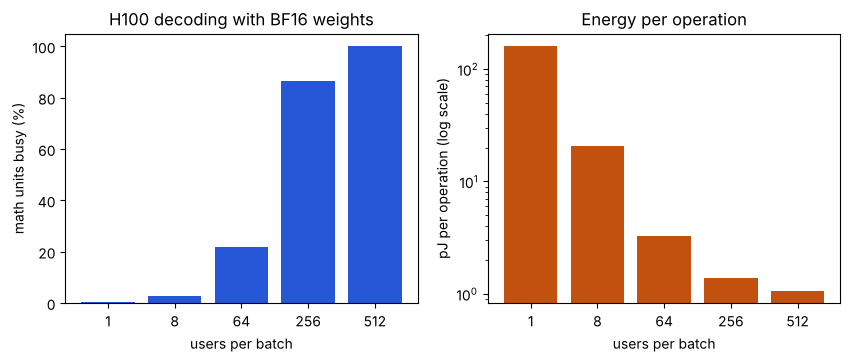

In [9]:
BYTES_PER_WEIGHT = 2
ridge_flops_per_byte = H100_BF16_FLOPS / H100_MEMORY_BANDWIDTH
print(f"Operations per byte needed to keep the math units busy: {ridge_flops_per_byte:.0f}")

def busy_share(batch_size):
    """Fraction of time the math units are busy when decoding a batch."""
    flops_per_byte = 2 * batch_size / BYTES_PER_WEIGHT
    return min(1.0, flops_per_byte / ridge_flops_per_byte)

batch_sizes = [1, 8, 64, 256, 512]
shares = [busy_share(b) for b in batch_sizes]
READ_PJ = 640 / 2           # one 2-byte weight from off-chip memory
MULTIPLY_ADD_PJ = 1.1 + 0.4 # one 16-bit multiply-add = 2 operations

def energy_per_operation(batch_size):
    """Picojoules per operation: the weight read is shared by the whole batch."""
    return READ_PJ / (2 * batch_size) + MULTIPLY_ADD_PJ / 2

energies = [energy_per_operation(b) for b in batch_sizes]
for b, share, energy in zip(batch_sizes, shares, energies):
    print(f"batch {b:4d}: {share:6.1%} busy, {energy:6.2f} pJ per operation")
print(f"Batch 512 uses {energies[0] / energies[-1]:.0f}x less energy per operation than batch 1")

fig, (ax_busy, ax_energy) = plt.subplots(1, 2, figsize=(10, 3.5))
labels = [str(b) for b in batch_sizes]
ax_busy.bar(labels, [100 * s for s in shares], color=BLUE)
ax_busy.set_xlabel("users per batch")
ax_busy.set_ylabel("math units busy (%)")
ax_busy.set_title("H100 decoding with BF16 weights")
ax_energy.bar(labels, energies, color=ORANGE)
ax_energy.set_yscale("log")
ax_energy.set_xlabel("users per batch")
ax_energy.set_ylabel("pJ per operation (log scale)")
ax_energy.set_title("Energy per operation")
plt.show()

## Cheaper inference: caching

First, how many token passes it takes to write a 1,000-word answer after a 1,000-word prompt, with and without a KV cache. Second, how much memory Kimi K2's cache needs, using the multi-head latent attention sizes it shares with DeepSeek-V3 (a 512-number latent plus 64 position numbers per layer, 61 layers, 2 bytes each in FP16).

In [10]:
prompt_tokens = 1000
answer_tokens = 1000

# Without a cache, writing token t means running all t tokens through the model again.
passes_without_cache = sum(range(prompt_tokens + 1, prompt_tokens + answer_tokens + 1))
passes_with_cache = prompt_tokens + answer_tokens
print(f"{passes_without_cache:,} vs {passes_with_cache:,} token passes: {passes_without_cache / passes_with_cache:.0f}x less work")

kv_bytes_per_token = (512 + 64) * 2 * 61
print(f"Kimi K2 KV cache: {kv_bytes_per_token:,} bytes per token, "
      f"{kv_bytes_per_token * 131072 / 1e9:.1f} GB for a 128k-token conversation")

1,500,500 vs 2,000 token passes: 750x less work
Kimi K2 KV cache: 70,272 bytes per token, 9.2 GB for a 128k-token conversation


## Smaller models: quantization, distillation, mixture of experts

Quantization: memory for a trillion weights at each width (the B200 throughput figures on the slide are NVIDIA's), and how many 128k-token conversations fit beside Kimi K2 on one 8 x B200 server (8 x 180 GB), ignoring other overhead. Distillation: DeepSeek-R1 (671B weights, 37B used per word) against its 7B distilled student. Mixture of experts: Kimi K2 uses 32B of its 1T weights per word.

In [11]:
server_gb = 8 * 180
kv_gb_per_user = 70272 * 131072 / 1e9
for name, bits in [("BF16", 16), ("FP8", 8), ("FP4", 4)]:
    weights_gb = 1e12 * bits / 8 / 1e9
    free_gb = server_gb - weights_gb
    users = max(0, int(free_gb // kv_gb_per_user))
    print(f"{name}: {weights_gb / 1000:.1f} TB of weights, room for {users} users")

print(f"Distillation: {37 / 7:.1f}x less math per word, {671 / 7:.0f}x less memory")

k2_total, k2_active = 1e12, 32e9
print(f"Mixture of experts: {k2_active / k2_total:.1%} of weights used per word, "
      f"{k2_total / k2_active:.0f}x less math than a dense model of the same size")

BF16: 2.0 TB of weights, room for 0 users
FP8: 1.0 TB of weights, room for 47 users
FP4: 0.5 TB of weights, room for 102 users
Distillation: 5.3x less math per word, 96x less memory
Mixture of experts: 3.2% of weights used per word, 31x less math than a dense model of the same size


## Research changes the curve: linear attention

Approximate operation counts for reading a whole context (causal prefill) in a model the size of Kimi K2: 61 layers, 64 heads, query/key size 192 and value size 128 for full attention. Linear attention is modelled as a gated delta-rule update on a 128 x 128 state per head, about 7 x 128 x 128 operations per token per head. Kimi Linear's hybrid uses one full-attention layer for every three linear ones. These are our estimates, not measurements; the published Kimi Linear results (75% less KV cache, up to 6x faster decoding at 1M tokens) are from the paper.

Full attention       1.4e+18 FLOPs =   1388.9 s on one H100 at peak
Kimi Linear hybrid   3.4e+17 FLOPs =    347.6 s on one H100 at peak
Linear attention     4.7e+14 FLOPs =      0.5 s on one H100 at peak
Rest of the model    6.7e+16 FLOPs =     67.9 s on one H100 at peak
Full attention costs more than the rest of the model beyond 51,230 tokens


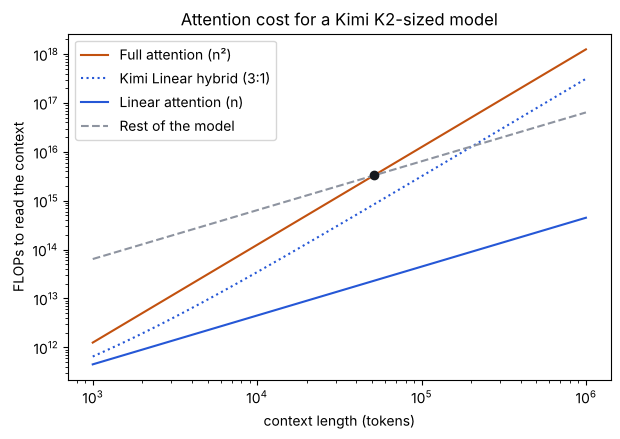

In [12]:
LAYERS, HEADS = 61, 64
QK_DIM, V_DIM = 192, 128
LINEAR_STATE = 128
ACTIVE_PARAMS = 32e9

def full_attention_flops(n):
    """Causal attention scores plus weighted sums: grows with n squared."""
    return LAYERS * HEADS * (QK_DIM + V_DIM) * n**2

def linear_attention_flops(n):
    """Fixed-size state updated once per token: grows with n."""
    return LAYERS * HEADS * 7 * LINEAR_STATE * LINEAR_STATE * n

def hybrid_flops(n):
    """Kimi Linear: one full-attention layer in four."""
    return 0.25 * full_attention_flops(n) + 0.75 * linear_attention_flops(n)

def rest_of_model_flops(n):
    """Projections and experts: about 2 operations per active weight per token."""
    return 2 * ACTIVE_PARAMS * n

n = 1_048_576
for name, flops in [("Full attention", full_attention_flops(n)),
                    ("Kimi Linear hybrid", hybrid_flops(n)),
                    ("Linear attention", linear_attention_flops(n)),
                    ("Rest of the model", rest_of_model_flops(n))]:
    print(f"{name:20s} {flops:.1e} FLOPs = {flops / H100_BF16_FLOPS:8.1f} s on one H100 at peak")

crossover = 2 * ACTIVE_PARAMS / (LAYERS * HEADS * (QK_DIM + V_DIM))
print(f"Full attention costs more than the rest of the model beyond {crossover:,.0f} tokens")

lengths = [10 ** (3 + i * 0.05) for i in range(61)]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(lengths, [full_attention_flops(x) for x in lengths], color=ORANGE, label="Full attention (n²)")
ax.loglog(lengths, [hybrid_flops(x) for x in lengths], color=BLUE, linestyle=":", label="Kimi Linear hybrid (3:1)")
ax.loglog(lengths, [linear_attention_flops(x) for x in lengths], color=BLUE, label="Linear attention (n)")
ax.loglog(lengths, [rest_of_model_flops(x) for x in lengths], color=GREY, linestyle="--", label="Rest of the model")
ax.scatter([crossover], [rest_of_model_flops(crossover)], color=INK, zorder=3)
ax.set_xlabel("context length (tokens)")
ax.set_ylabel("FLOPs to read the context")
ax.set_title("Attention cost for a Kimi K2-sized model")
ax.legend()
plt.show()